In [ ]:
# Projekt 10 – Bodenatmung
# Modellvalidierung

# Pakete laden
library(boot)   #Funtkion fuer Cross validation
library(lmtest) #Breusch-Pagan-test -> "Tests zur Pruefung von Heteroskedastizitaet" 

# Daten einlesen
hainich.data <- read.csv("hainich.csv", sep=";")




Call:
lm(formula = log(soil.res) ~ smoi + I(smoi^2) + lmoi + I(lmoi^2) + 
    soilc0 + I(soilc0^2) + I(litdoc^2) + rootdw0 + I(rootdw0^2) + 
    rootc5, data = hainich.data)

Residuals:
      Min        1Q    Median        3Q       Max 
-0.234111 -0.118037 -0.006095  0.117311  0.297293 

Coefficients:
               Estimate Std. Error t value Pr(>|t|)   
(Intercept)   9.242e+00  3.962e+00   2.333  0.02736 * 
smoi         -2.331e-01  1.079e-01  -2.161  0.03973 * 
I(smoi^2)     3.175e-03  1.480e-03   2.146  0.04101 * 
lmoi         -1.835e+01  9.741e+00  -1.884  0.07038 . 
I(lmoi^2)     1.741e+01  8.287e+00   2.101  0.04511 * 
soilc0        5.322e-02  2.061e-02   2.583  0.01555 * 
I(soilc0^2)  -3.164e-04  1.479e-04  -2.139  0.04166 * 
I(litdoc^2)   5.001e-01  1.585e-01   3.156  0.00391 **
rootdw0      -8.557e+00  3.197e+00  -2.677  0.01248 * 
I(rootdw0^2)  5.727e+01  1.764e+01   3.246  0.00312 **
rootc5       -3.409e-02  1.396e-02  -2.443  0.02140 * 
---
Signif. codes:  0 ‘***’ 0.001 ‘*


Call:
lm(formula = log(soil.res) ~ smoi + I(smoi^2) + lmoi + I(lmoi^2) + 
    soiln5 + I(soiln5^2) + soilc0 + I(soilc0^2) + soilc5 + I(soilc5^2) + 
    I(sno35^2) + I(litdoc^2) + rootdw0 + I(rootdw0^2) + rootdw5 + 
    I(rootdw5^2) + temp.0 + I(temp.0^2) + temp.15 + I(temp.15^2) + 
    rootc5, data = hainich.data)

Residuals:
      Min        1Q    Median        3Q       Max 
-0.195654 -0.053687  0.005898  0.052202  0.252513 

Coefficients:
               Estimate Std. Error t value Pr(>|t|)    
(Intercept)   2.473e+02  1.659e+02   1.490 0.155599    
smoi         -2.619e-01  1.040e-01  -2.518 0.022850 *  
I(smoi^2)     3.434e-03  1.421e-03   2.417 0.027933 *  
lmoi         -2.921e+01  1.183e+01  -2.468 0.025229 *  
I(lmoi^2)     2.692e+01  1.027e+01   2.621 0.018534 *  
soiln5        9.864e-01  5.801e-01   1.700 0.108415    
I(soiln5^2)  -1.862e-01  9.148e-02  -2.036 0.058669 .  
soilc0        5.576e-02  2.055e-02   2.713 0.015358 *  
I(soilc0^2)  -3.182e-04  1.515e-04  -2.101 0.05184

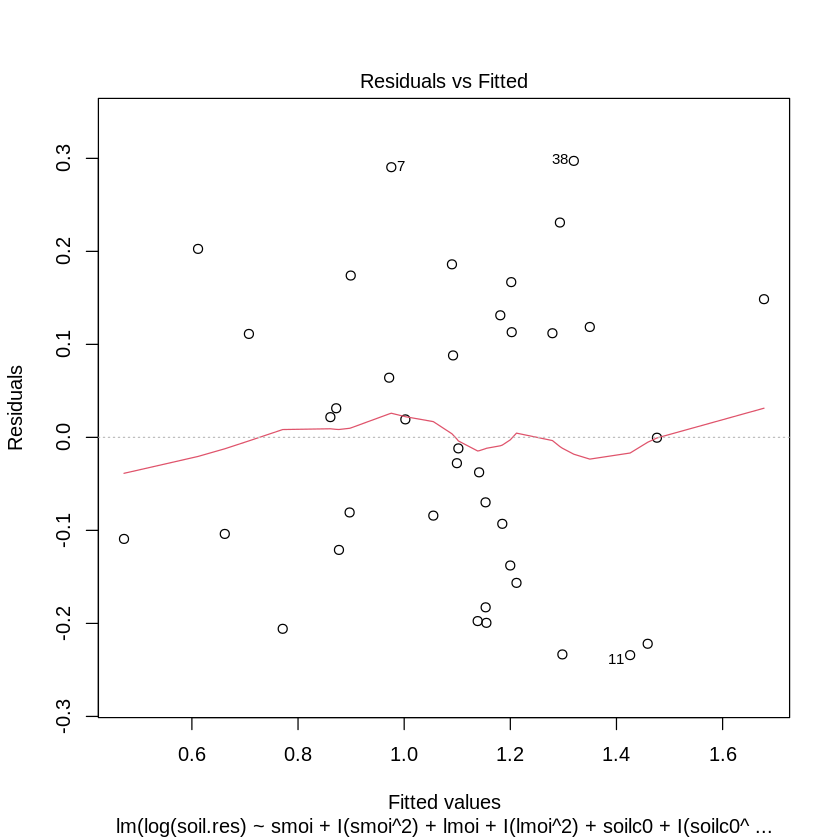

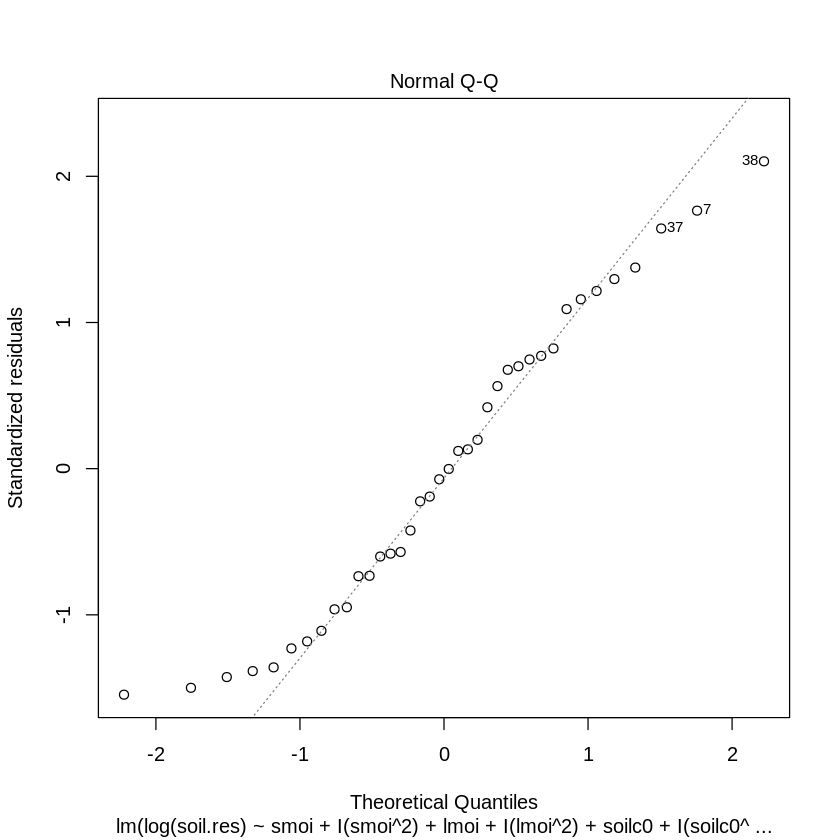

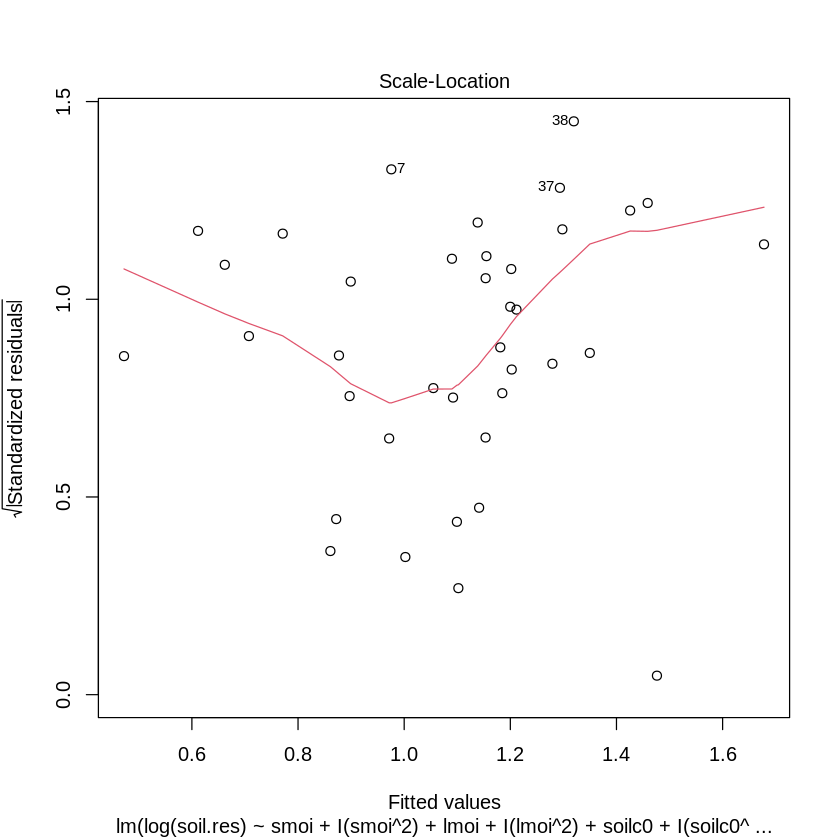

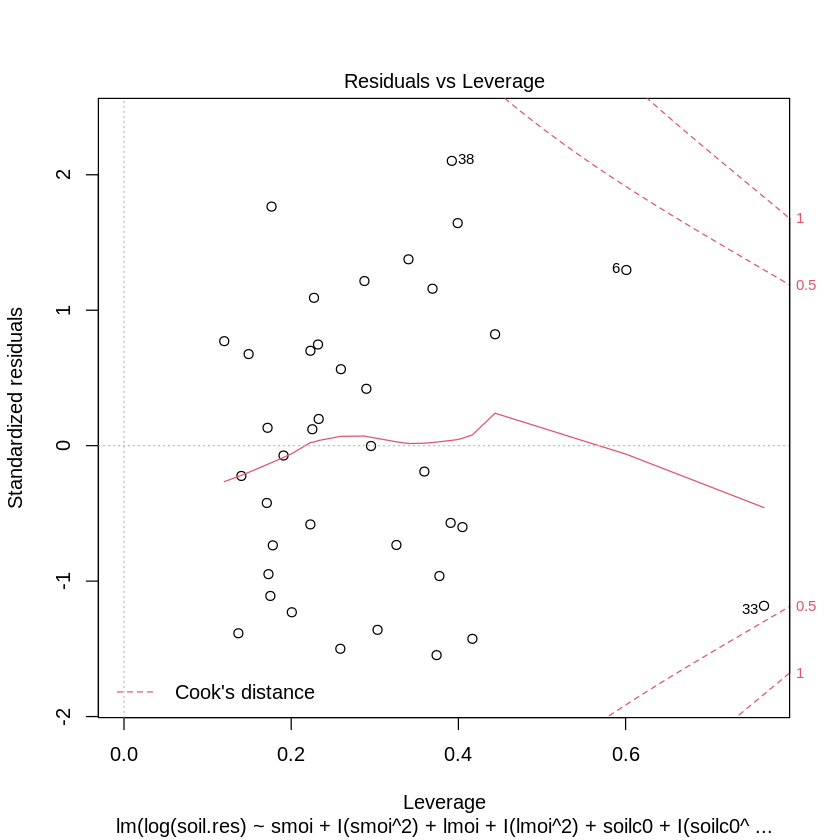

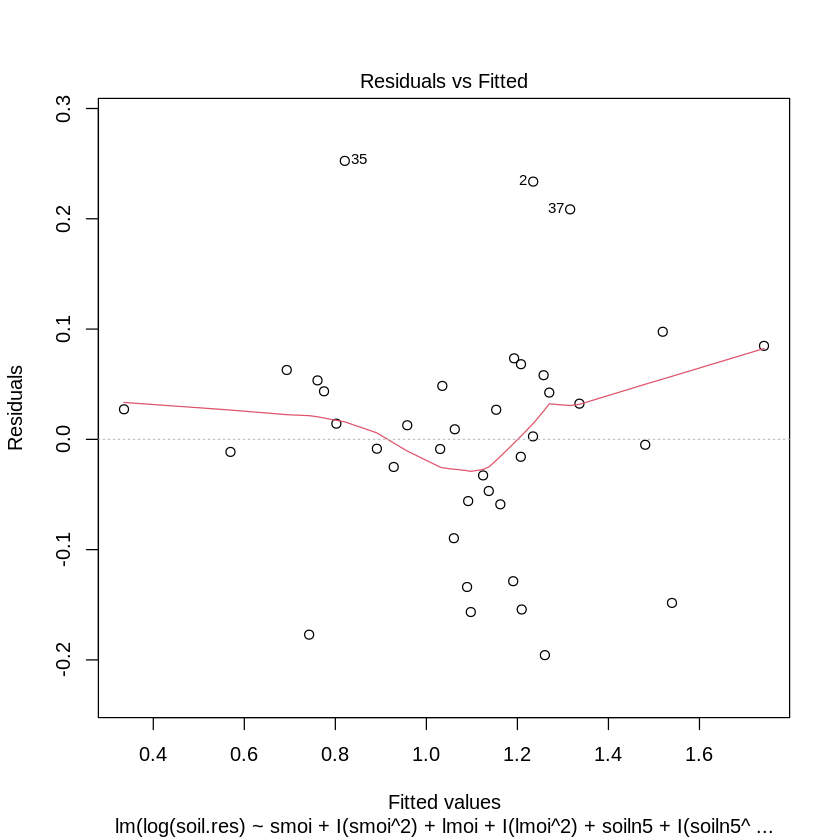

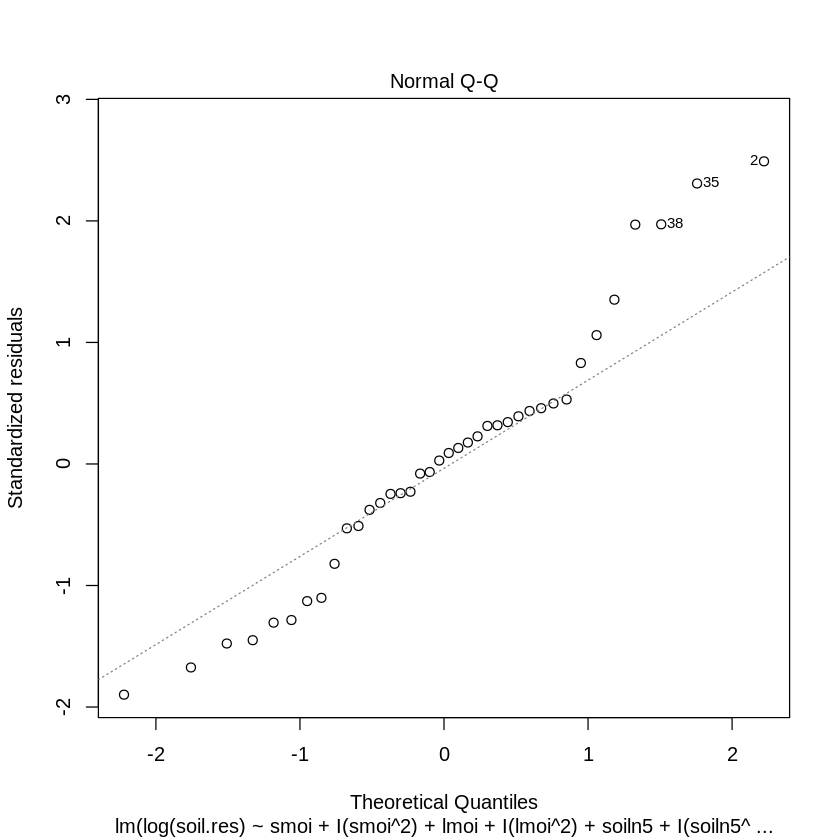

Warning message in sqrt(crit * p * (1 - hh)/hh):
“NaNs produced”
Warning message in sqrt(crit * p * (1 - hh)/hh):
“NaNs produced”


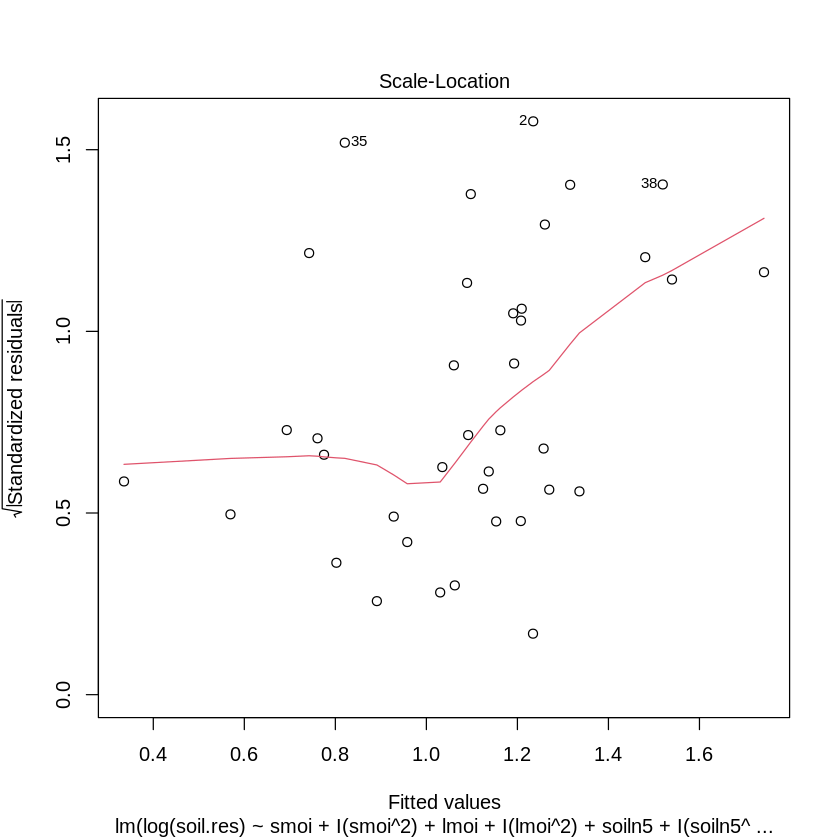

- signifikante Einflussfaktoren: smoi, smoi^2, lmoi^2, soilc0, soilc0^2, litdoc^2, rootdw0, rootdw0^2, rootc5
 - linearer Effekt von lmoi ist nur schwach signifikant (p ≈ 0.07), bleibt aber wegen des quadratischen Terms im Modell
 - mehrere signifikante Quadratterme zeigen nichtlineare Zusammenhaenge zwischen Umweltvariablen und Bodenatmung
 - Modell erklaert ca. 73 % der Variation der Bodenatmung (R^2 = 0.727)
 - adjustiertes Bestimmtheitsmass = 0.626 -> beruecksichtigt Anzahl der Praediktoren
 - globaler F-Test ist hochsignifikant (p < 0.001) -> Modell erklaert Zielgroesse insgesamt signifikant
 - Residual Standard Error etwa 0.18 -> typische Modellabweichung auf der Log-Skala


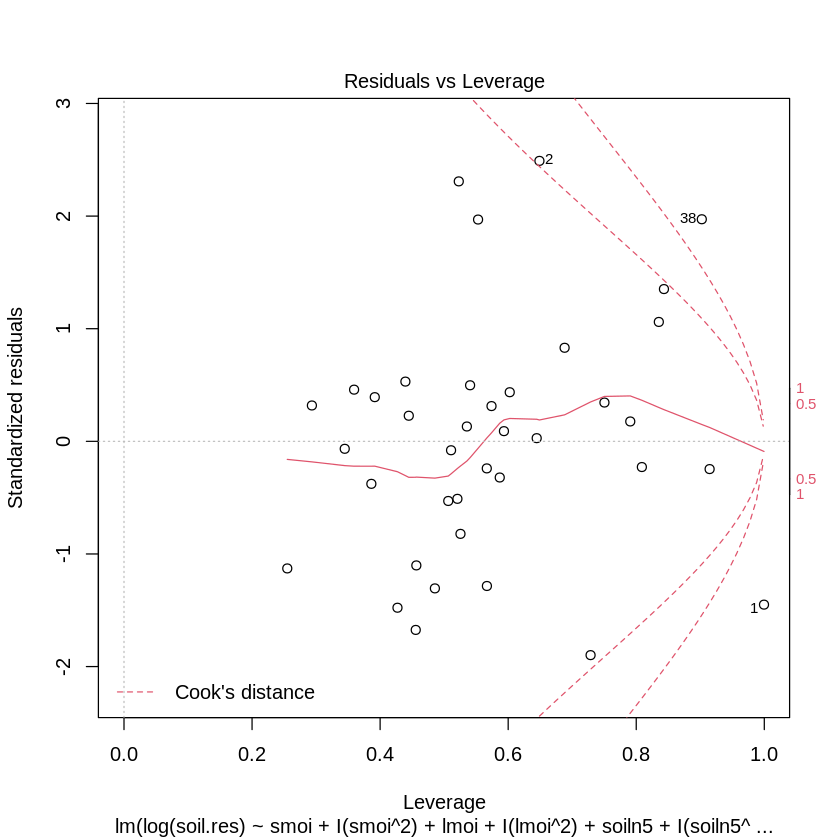

In [ ]:
#best-Modell (Modell aus Teil 1) wird validiert
#evtl. aendern, falls modell nochmals angepasst wird

best_model <- lm(log(soil.res) ~ smoi + I(smoi^2) + lmoi + I(lmoi^2) + soilc0 + I(soilc0^2) + I(litdoc^2)
                 + rootdw0 + I(rootdw0^2) + rootc5, data = hainich.data)

best_model_interaktion5 <- lm(log(soil.res) ~ I(lmoi^2) * soilc0 +
    I(soilc0^2) + I(temp.15^2) + I(rootdw0^2) + I(litter.d^2), data = hainich.data)
    
model_big <- lm(log(soil.res) ~ smoi + I(smoi^2) + lmoi + I(lmoi^2) +
    soiln5 + I(soiln5^2) + soilc0 + I(soilc0^2) + soilc5 + I(soilc5^2) +
    I(sno35^2) + I(litdoc^2) + rootdw0 + I(rootdw0^2) + rootdw5 +
    I(rootdw5^2) + temp.0 + I(temp.0^2) + temp.15 + I(temp.15^2) +
    rootc5,
    data = hainich.data)

# Modellübersicht
summary(best_model)
summary(model_big)

# Diagnostikplots des Modells
plot(best_model)
plot(model_big)

cat(
"- signifikante Einflussfaktoren: smoi, smoi^2, lmoi^2, soilc0, soilc0^2, litdoc^2, rootdw0, rootdw0^2, rootc5\n",
"- linearer Effekt von lmoi ist nur schwach signifikant (p ≈ 0.07), bleibt aber wegen des quadratischen Terms im Modell\n",
"- mehrere signifikante Quadratterme zeigen nichtlineare Zusammenhaenge zwischen Umweltvariablen und Bodenatmung\n",
"- Modell erklaert ca. 73 % der Variation der Bodenatmung (R^2 = 0.727)\n",
"- adjustiertes Bestimmtheitsmass = 0.626 -> beruecksichtigt Anzahl der Praediktoren\n",
"- globaler F-Test ist hochsignifikant (p < 0.001) -> Modell erklaert Zielgroesse insgesamt signifikant\n",
"- Residual Standard Error etwa 0.18 -> typische Modellabweichung auf der Log-Skala\n"
)

In [53]:
#Hilfsfunktionen
#RMSE: misst durchschnittlichen quadratischen Vorhersagefehler
#je kleiner Wert, desto besser passt Modell zu Daten
rmse <- function(y, yhat){
  sqrt(mean((y - yhat)^2))
}

#MAE: mittlerer absoluter Vorhersagefehler
#weniger empfindlich gegenüber Ausreißern als RMSE
mae <- function(y, yhat){
  mean(abs(y - yhat))
}

#zUusammenstellung wichtiger Modellkennzahlen
#liefert zentrale Maße zur Bewertung des Modells
model_metrics <- function(model){
  
  #beobachtete Werte Zielgroeße
  y <- model.response(model.frame(model))
  
  #vorhergesagte Werte Modell
  yhat <- predict(model)
  
  out <- c(
    n = length(y),                         #Anzahl Beobachtungen
    p = length(coef(model)) - 1,           #"-" Praediktoren
    RMSE = rmse(y, yhat),                  #quadratischer Prognosefehler
    MAE = mae(y, yhat),                    #absoluter Prognosefehler
    AIC = AIC(model),                      #Informationskriterium
    BIC = BIC(model)                       #Informationskriterium
  )
  
  return(out)
}

# LOOCV (Leave-One-Out Cross Validation): Modell wird n-mal geschaetzt, jeweils eine Beobachtung weggelassen
#liefert robuste Schaetzung Prognosefehlers
cv_rmse_loocv <- function(formula, data){
  glm.fit <- glm(formula, data = data)
  cv.out <- cv.glm(data, glm.fit)
  sqrt(cv.out$delta[1])
}

#k-fold Cross Validation: datensatz wird in k Teile aufgeteilt
#Modell wird k-mal trainiert und getestet
cv_rmse_kfold <- function(formula, data, K = 10){
  glm.fit <- glm(formula, data = data)
  cv.out <- cv.glm(data, glm.fit, K = K)
  sqrt(cv.out$delta[1])
}

model_metrics(best_model)
model_metrics(model_big)

cv_rmse_loocv(formula(best_model), hainich.data)
cv_rmse_loocv(formula(model_big), hainich.data)

cv_rmse_kfold(formula(best_model), hainich.data, K = 10)
cv_rmse_kfold(formula(model_big), hainich.data, K = 10)

n           p        RMSE         MAE         AIC         BIC 
 38.0000000  10.0000000   0.1528678   0.1320038 -10.9024938   8.7485401

n            p         RMSE          MAE          AIC          BIC 
 38.00000000  21.00000000   0.10276900   0.07646837 -19.08130696  18.58317471

[1] 0.2343161

[1] 1.76786

[1] 0.2368106

[1] 2.559542

In [66]:
#cross validation fuer das reduzierte modell
rmse_loocv  <- cv_rmse_loocv(formula(best_model), hainich.data)
rmse_10fold <- cv_rmse_kfold(formula(best_model), hainich.data, K = 10)

print(rmse_loocv) #durchschnittlicher vorhersagefeher
print(rmse_10fold)#durchschnittlicher fehler

#.. fuer das grosse Modell
rmse_loocv_big  <- cv_rmse_loocv(formula(model_big), hainich.data)
rmse_10fold_big <- cv_rmse_kfold(formula(model_big), hainich.data, K = 10)

print(rmse_loocv_big)
print(rmse_10fold_big)
cat(
"- Trainings RMSE: 0.15; LOOCV RMSE: 0.23; 10-fold RMSe: 0.24   -> fehler fuer neue daten ist groeßer als im Training\n",
"- deutlich groeßerer vorhersagefehler fuer großes modell -> overfitting")


[1] 0.2343161
[1] 0.2388212
[1] 1.76786
[1] 2.012531
- Trainings RMSE: 0.15; LOOCV RMSE: 0.23; 10-fold RMSe: 0.24   -> fehler fuer neue daten ist groeßer als im Training
 - deutlich groeßerer vorhersagefehler fuer großes modell -> overfitting

In [69]:
#Test auf Normalverteilung Residuen
#mit shapiro wilk test
#reduziertes mdoel
print(shapiro.test(residuals(best_model)))

#test auf konstante Varianz residuen
#breusch pagan test: Tests zur Pruefung von Heteroskedastizitaet.
#reduziertes modell
print(bptest(best_model))

#model_big: shapiro
print(shapiro.test(residuals(model_big)))
#model_big:breusch
print(bptest(model_big))



cat(
"- Shapiro: gibt keinen statistischen Hinweis, dass die Residuen nicht normalverteilt sind -> Normalitaetsannahme plausibel erfuellt\n",
"-> passt typischerweise auch zum QQ-Plot, wenn die Punkte ungefaehr auf der Linie liegen\n",
"- Breusch-Pagan-Test: keine Hinweise auf Heteroskedastizitaet -> Residuen haben ungefaehr konstante Varianz\n"
)


	Shapiro-Wilk normality test

data:  residuals(best_model)
W = 0.95678, p-value = 0.1489


	studentized Breusch-Pagan test

data:  best_model
BP = 9.3737, df = 10, p-value = 0.497


	Shapiro-Wilk normality test

data:  residuals(model_big)
W = 0.95019, p-value = 0.09032


	studentized Breusch-Pagan test

data:  model_big
BP = 26.847, df = 21, p-value = 0.176

- Shapiro: gibt keinen statistischen Hinweis, dass die Residuen nicht normalverteilt sind -> Normalitaetsannahme plausibel erfuellt
 -> passt typischerweise auch zum QQ-Plot, wenn die Punkte ungefaehr auf der Linie liegen
 - Breusch-Pagan-Test: keine Hinweise auf Heteroskedastizitaet -> Residuen haben ungefaehr konstante Varianz


In [71]:
#beobachten (wichtige)
#cook's Distance misst Einfluss einzelner Beobachtungen
cook <- cooks.distance(best_model)

#typische Schwelle
cook.limit <- 4 / nrow(hainich.data)

print(which(cook > cook.limit))
cook.limit

cat(
"- beobachtungen mit Cook's Distance >4 gelten als potenziell einflussreich\n",
"-> Beobachtungen 4, 6, 8, 33, 37, 38 ueberschrieten Schwelle\n",
"-> Punkte koennen einen relativ starken Einfluss auf Modellschaetzung haben\n"
)

 4  6  8 33 37 38 
 4  6  8 33 37 38 


[1] 0.1052632

- beobachtungen mit Cook's Distance >4 gelten als potenziell einflussreich
 -> Beobachtungen 4, 6, 8, 33, 37, 38 ueberschrieten Schwelle
 -> Punkte koennen einen relativ starken Einfluss auf Modellschaetzung haben


In [72]:
# beobachtete und vorhergesagte Werte
y <- model.response(model.frame(best_model))
yhat <- predict(best_model)

# Prognoseintervalle
pred.int <- predict(best_model, interval = "prediction")
head(pred.int)

#model-big
y <- model.response(model.frame(model_big))
yhat <- predict(model_big)
pred.int <- predict(model_big, interval = "prediction")
head(pred.int)

cat(
"- vorhergesagten Werte (fit) liegen für ersten Beobachtungen zw. 1.14 und 1.68 auf Log-Skala\n",
"- zugehoerigen Prognoseintervalle von ca. 0.70 bis 2.15\n",
"- tatsaechlichen Werte Bodenatmung sollten fuer diese Beobachtungen mit hohe wkt. innerhalb Intervalle liegen\n",
"- Intervalle sind relativ breit -> gewisse Unsicherheit der Vorhersagen\n",
"-> liefert Modell plausible Vorhersagen (beruecksichtigt natuerliche Streuung der Daten)\n"
)


Warning message in predict.lm(best_model, interval = "prediction"):
“predictions on current data refer to _future_ responses
”


,fit,lwr,upr
1,1.476258,1.0527275,1.899789
2,1.349744,0.9367109,1.762777
3,1.184865,0.7733681,1.596362
4,1.138479,0.6955750,1.581383
5,1.154914,0.7471655,1.562662
6,1.677973,1.2071609,2.148785


Warning message in predict.lm(model_big, interval = "prediction"):
“predictions on current data refer to _future_ responses
”


,fit,lwr,upr
1,1.480818,1.0060561,1.955580
2,1.234730,0.8036108,1.665850
3,1.124612,0.7016745,1.547549
4,1.097578,0.6561401,1.539015
5,1.089391,0.6691339,1.509649
6,1.741797,1.2859627,2.197631


- vorhergesagten Werte (fit) liegen für ersten Beobachtungen zw. 1.14 und 1.68 auf Log-Skala
 - zugehoerigen Prognoseintervalle von ca. 0.70 bis 2.15
 - tatsaechlichen Werte Bodenatmung sollten fuer diese Beobachtungen mit hohe wkt. innerhalb Intervalle liegen
 - Intervalle sind relativ breit -> gewisse Unsicherheit der Vorhersagen
 -> liefert Modell plausible Vorhersagen (beruecksichtigt natuerliche Streuung der Daten)


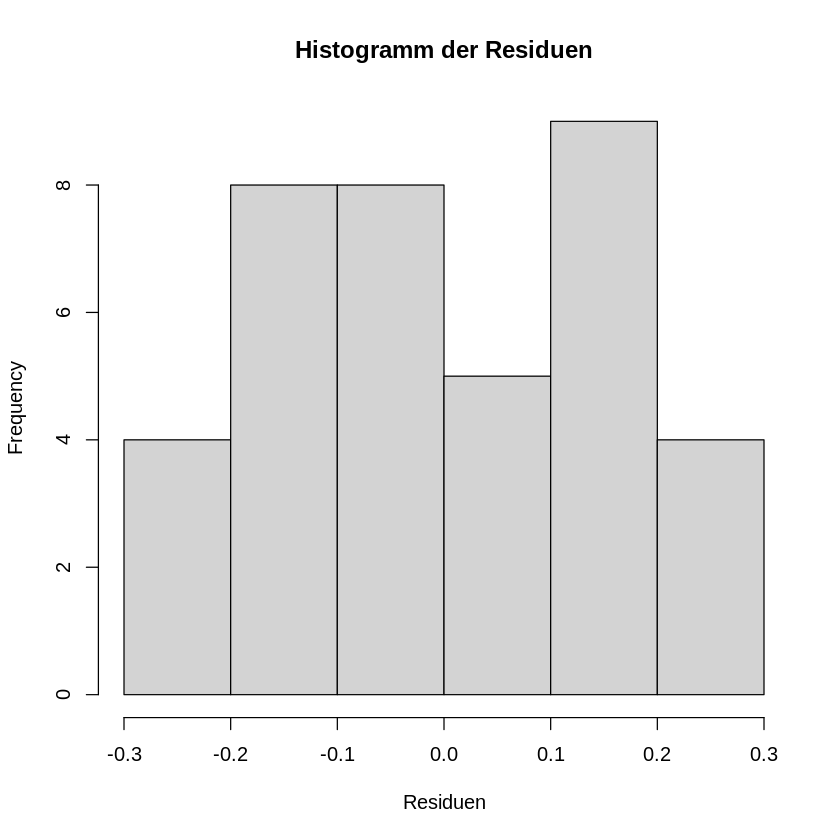

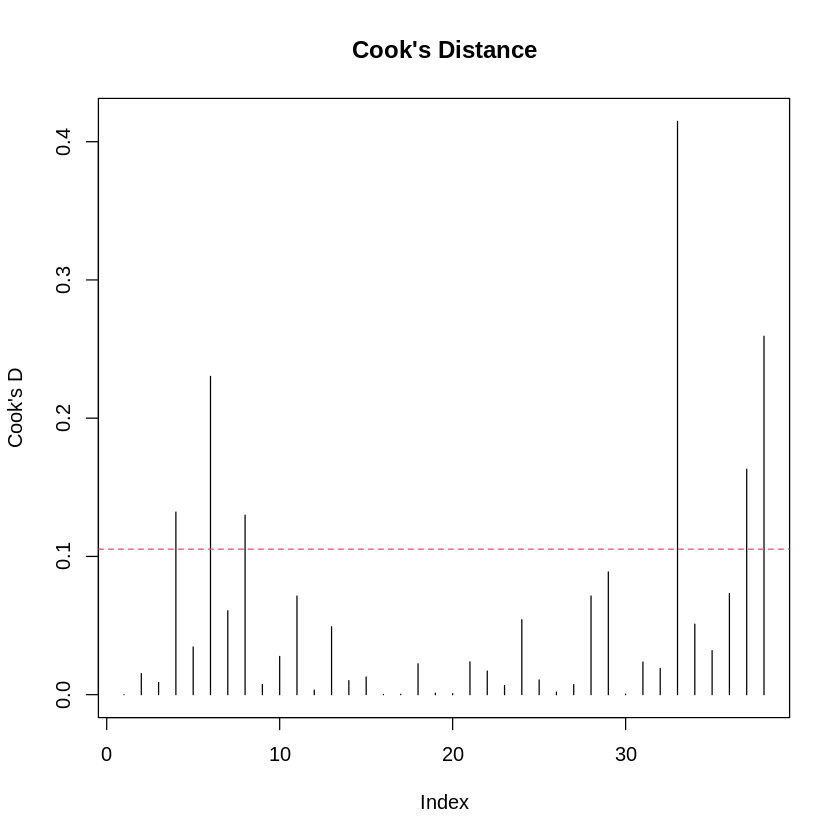

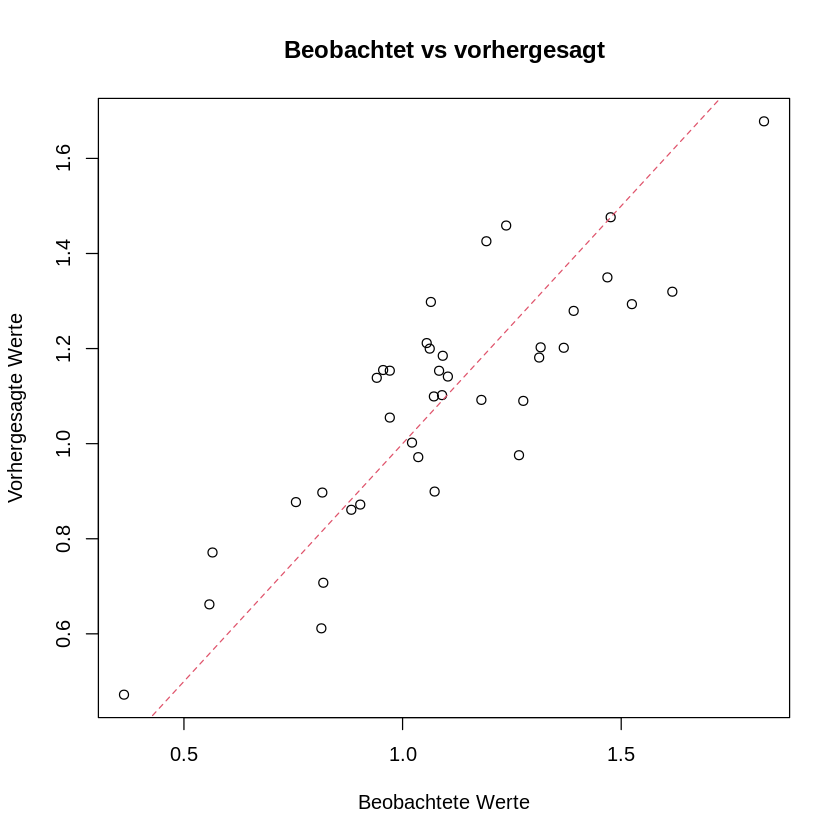

In [35]:
#-> plots
#Histogramm der Residue
hist(residuals(best_model),
     main = "Histogramm der Residuen",
     xlab = "Residuen")

#cooks distanz plot
plot(cook, type = "h",
     main = "Cook's Distance",
     ylab = "Cook's D")
abline(h = cook.limit, col = 2, lty = 2)

#beobachtet vs vohergesagt
plot(y, yhat,
     xlab = "Beobachtete Werte",
     ylab = "Vorhergesagte Werte",
     main = "Beobachtet vs vorhergesagt")
abline(0, 1, col = 2, lty = 2)


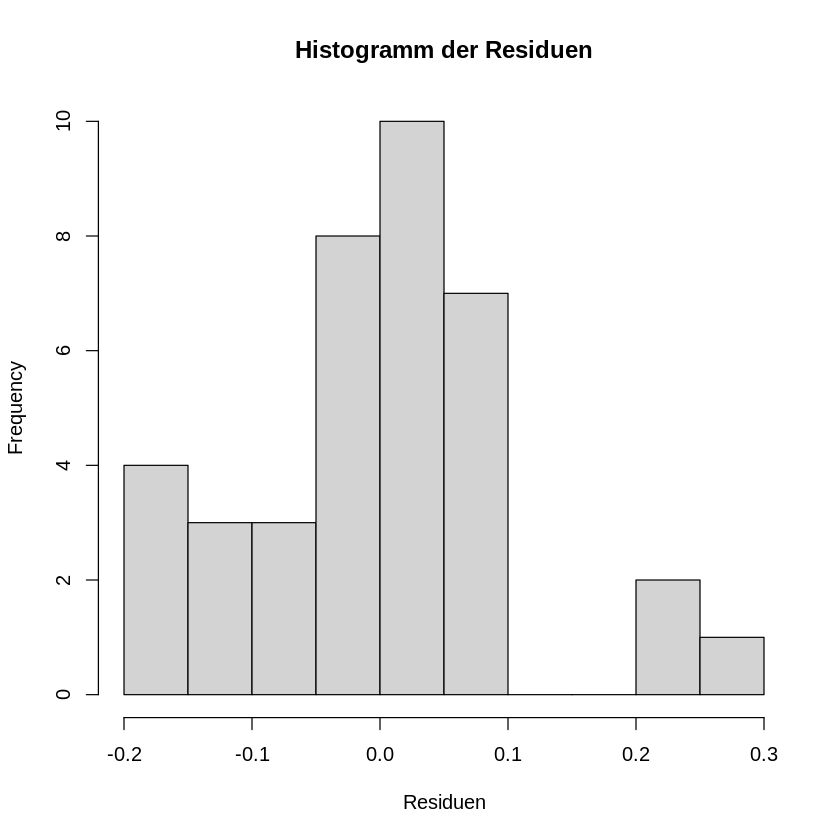

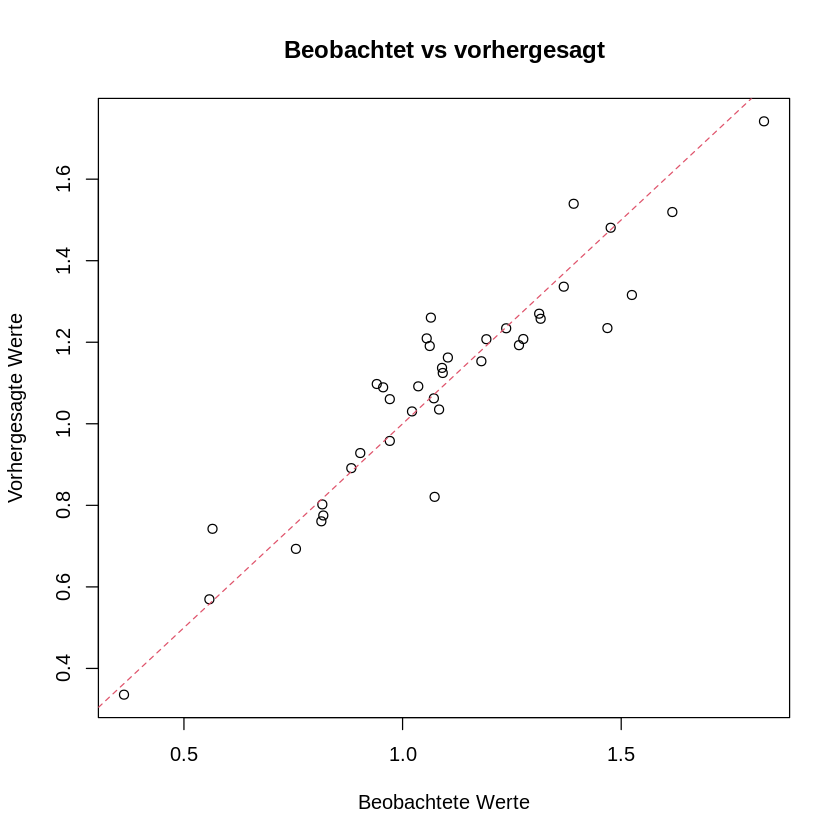

In [74]:
#-> plots
#Histogramm der Residue
hist(residuals(model_big),
     main = "Histogramm der Residuen",
     xlab = "Residuen")

#beobachtet vs vohergesagt
plot(y, yhat,
     xlab = "Beobachtete Werte",
     ylab = "Vorhergesagte Werte",
     main = "Beobachtet vs vorhergesagt")
abline(0, 1, col = 2, lty = 2)